In [1]:
from glob import glob

import matplotlib.gridspec as gridspec
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
from toolbox import evaluate_combinations, get_freqs, visualize_Category_hist
from toolbox.loading import load_data
from toolbox.visualization import cmap_gradient

# Data statistics

In [2]:
(
    py_idx,
    patient_no,
    patient_sample,
    Zdata,
    _,
    LesionAssessment,
    label_healthy_vs_cancer,
    label_cancer_vs_hbd,
    label_MC,
) = load_data(path="data", Cutpats_threshold=60, norm="freq")


	Info:	np.abs(Zdata)

Remaining data samples: 276 
	Info:	Select only data Avg_Cutpats <60%

Remaining data samples: 260 

	Info:	z-score Zdata
before: 443.1566344679978 707.062822308054
Normalized along the frequency axis.

after: -5.841877056904085e-18 0.9999999999999997

	Info:	np.nan_to_num(Zdata)

Remaining data samples: 260 


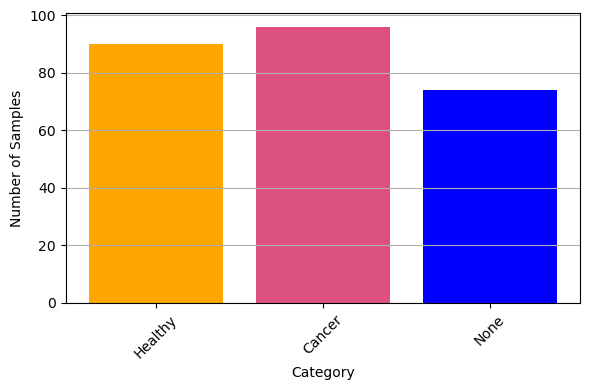

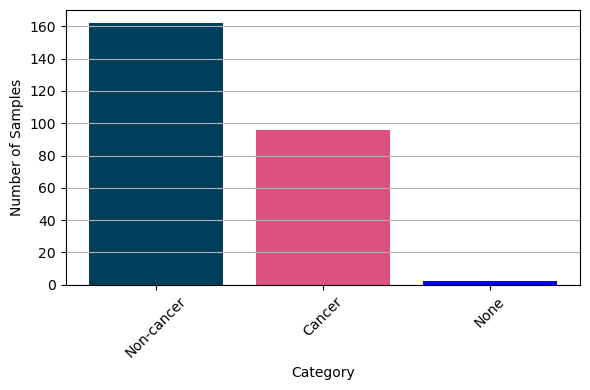

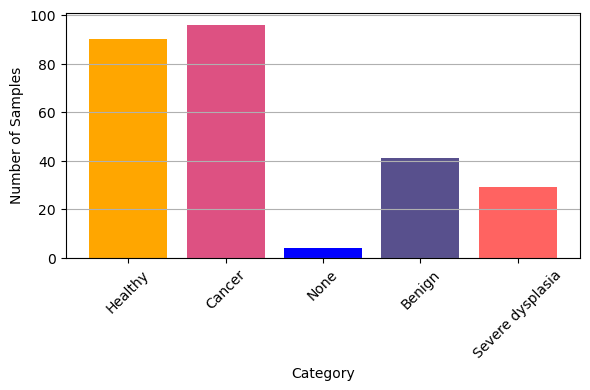

In [3]:
visualize_Category_hist(
    label_healthy_vs_cancer, s_name="results/hist_healthy_vs_cancer.pdf"
)
visualize_Category_hist(label_cancer_vs_hbd, s_name="results/hist_cancer_vs_hbd.pdf")
visualize_Category_hist(label_MC, s_name="results/hist_MC.pdf")

# Model selection

In [4]:
Fsel = "All"
Msel = "All"

class_task = "healthy_vs_cancer"
# class_task = "cancer_vs_hbd"
# class_task = "MC"

df = pd.read_csv(f"results/LPOCV_{class_task}_{Fsel}_{Msel}_model_HPT.csv")

In [5]:
# Suppose df_avg is your averaged DataFrame
metrics = ["ROC AUC", "Recall", "F1-score"]
df_avg = df.groupby(["Architecture"])[metrics].mean().reset_index()

df_melt = df_avg.melt(
    id_vars=["Architecture"],
    value_vars=metrics,
    var_name="Metric",
    value_name="Score",
)

df_avg = df.groupby(["Architecture"])[metrics].mean().reset_index()

print("Average performance:\n", df_avg)

Average performance:
                  Architecture   ROC AUC    Recall  F1-score
0      DecisionTreeClassifier  0.718424  0.715342  0.715716
1  GradientBoostingClassifier  0.876471  0.808298  0.808107
2                          LR  0.853493  0.800992  0.801018
3                          RF  0.896930  0.818872  0.819065
4                         SVM  0.883983  0.836183  0.836305


C:\Users\f005cgg\AppData\Local\anaconda3\envs\machine_learning\Lib\site-packages\seaborn\axisgrid.py:118: UserWarning: The figure layout has changed to tight
  self._figure.tight_layout(*args, **kwargs)
C:\Users\f005cgg\AppData\Local\Temp\ipykernel_14164\524524292.py:19: UserWarning: The figure layout has changed to tight
  plt.tight_layout()


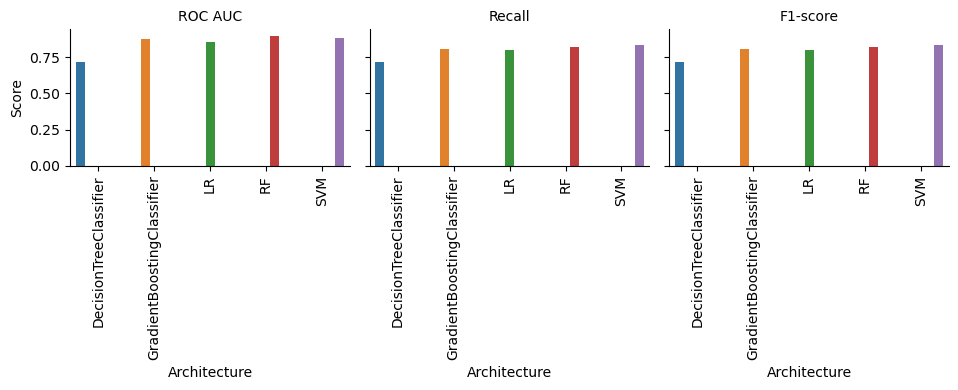

In [6]:
g = sns.catplot(
    data=df_melt,
    x="Architecture",
    y="Score",
    hue="Architecture",
    col="Metric",
    kind="bar",
    height=4,
    aspect=0.8,
)

g.set_titles("{col_name}")
g.set_axis_labels("Architecture", "Score")

# Rotate x tick labels
for ax in g.axes.flat:
    ax.set_xticklabels(ax.get_xticklabels(), rotation=90)

plt.tight_layout()
plt.show()

# Frequency reduction

In [70]:
# class_task = "healthy_vs_cancer"
# class_task = "cancer_vs_hbd"
# class_task = "MC"

In [7]:
tmp = np.load(f"results/freq_fold_results_{class_task}.npz", allow_pickle=True)
fold_rankings_baseline = tmp["fold_rankings_baseline"]
aucs_baseline = tmp["aucs_baseline"]
top_freqs_baseline = tmp["top_freqs_baseline"]
fold_aucs_baseline = tmp["fold_aucs_baseline"].tolist()

ModuleNotFoundError: No module named 'numpy._core'

In [ ]:
def plot_fold_rankings(fold_rankings_dict, top_n_freqs=20, class_task="unnamed"):
    """
    Visualizes fold frequency rankings as heatmaps for multiple ranking sets.

    Parameters:
        fold_rankings_dict : dict
            Dictionary where keys are method names and values are lists of np.arrays (fold rankings).
        top_n_freqs : int
            Number of top composite frequencies to display in the heatmap.
    """
    for name, rankings in fold_rankings_dict.items():
        n_folds = len(rankings)
        n_freqs = len(rankings[0])

        # Composite ranking across folds for sorting
        score_accumulator = np.zeros(n_freqs)
        for fold in rankings:
            for rank, freq_idx in enumerate(fold):
                score_accumulator[freq_idx] += n_freqs - rank

        composite_ranking = np.argsort(score_accumulator)[::-1][:top_n_freqs]

        # Create rank matrix: rows = top freqs, cols = folds
        rank_matrix = np.full((top_n_freqs, n_folds), np.nan)
        for f_idx, fold in enumerate(rankings):
            for i, freq in enumerate(composite_ranking):
                pos = np.where(fold == freq)[0]
                if pos.size > 0:
                    rank_matrix[i, f_idx] = pos[0] + 1  # +1 for 1-based rank

        plt.figure(figsize=(9, 7))
        sns.heatmap(
            rank_matrix,
            annot=True,
            fmt=".0f",
            cmap=cmap_gradient,
            cbar_kws={"label": "Rank Position (lower is better)"},
            xticklabels=[f"Fold {i+1}" for i in range(n_folds)],
            yticklabels=[f"Freq {f+1}" for f in composite_ranking],
            annot_kws={"fontsize": 14},
        )
        plt.xlabel("Fold", fontsize=14)
        plt.ylabel("Top Frequencies", fontsize=14)

        plt.xticks(fontsize=12)  # rotate if needed
        plt.yticks(fontsize=12)
        plt.tight_layout()
        plt.savefig(
            f"results/Fold-wise_frequency_impact_rankings_{name}_{class_task}.pdf",
            bbox_inches="tight",
        )
        plt.show()


fold_rankings_dict = {
    "Baseline": fold_rankings_baseline,
    # "Long-across": fold_rankings_la,
    # "Long-across extend": fold_rankings_lae,
    # "Skip 1": fold_rankings_s1,
}

plot_fold_rankings(fold_rankings_dict, top_n_freqs=31, class_task=class_task)

In [ ]:
# Plot AUC vs number of frequencies
plt.figure(figsize=(6, 3))
plt.plot(
    range(1, 31 + 1),
    np.nanmean([np.array(v) for v in fold_aucs_baseline.values()], axis=0),
    marker="x",
    color="steelblue",
    linewidth=2,
    label="Mean AUC",
)

# Add individual fold lines
for fold_idx in range(5):
    plt.plot(
        range(1, 31 + 1),
        fold_aucs_baseline[fold_idx],
        "o-",
        alpha=0.3,
        label=f"Fold {fold_idx+1}",
    )

plt.xlabel("Number of top frequencies $\mathbf{f}_\mathrm{T}$")
plt.xticks(range(1, 31 + 1, 3))
plt.ylabel("AUC")
plt.grid(True)
plt.legend(loc="lower right")
plt.tight_layout()
plt.savefig(f"results/baselineaucs_{class_task}.pdf", bbox_inches="tight")
plt.show()

In [ ]:
freq_idx, freq_list = get_freqs(plot=False)

In [ ]:
top_2 = top_freqs_baseline[:2]
top_3 = top_freqs_baseline[:3]
top_5 = top_freqs_baseline[:5]
top_12 = top_freqs_baseline[:12]

In [ ]:
plt.figure(figsize=(6, 3))
plt.plot(freq_list[freq_idx], freq_idx + 1, ".", c="#003F5C", ms=6, label="All")
plt.plot(freq_list[top_2], top_2 + 1, "o", c="#58508D", ms=9.5, label="Top 2")
plt.plot(freq_list[top_3], top_3 + 1, "x", c="#7A5195", ms=9.5, label="Top 3")
plt.plot(freq_list[top_5], top_5 + 1, "X", c="#FF6361", ms=8, label="Top 5")
plt.plot(freq_list[top_12], top_12 + 1, "*", c="#FFA600", ms=8, label="Top 12")
plt.legend()
plt.grid()
plt.xlabel("Frequency (Hz)")
plt.yticks(range(1, 31 + 1, 3))
plt.xscale("log")
plt.ylabel("Frequency index")
plt.tight_layout()
plt.savefig(f"results/freq_topX_{class_task}.pdf", bbox_inches="tight")
plt.show()

In [ ]:
class_task = "healthy_vs_cancer"
#class_task = "cancer_vs_hbd"
#class_task = "MC"

df_results = pd.read_csv(f"results/freq-analysis_{class_task}.csv")
df_params = pd.read_csv(f"results/freq-analysis_{class_task}_params.csv")

In [ ]:
df_pivot = df_results.pivot(index="Fsel", columns="Trial", values="avg. ROC AUC")
df_results_avg = df_pivot.mean(axis=1).reset_index()
df_results_avg.columns = ["Fsel", "avg. ROC AUC"]
df_plot = pd.merge(df_params, df_results_avg, on="Fsel")

if class_task == "MC":
    fig = plt.figure(figsize=(9.25, 3))
else:
    fig = plt.figure(figsize=(9, 3))
gs = gridspec.GridSpec(1, 2, width_ratios=[2, 1], wspace=0.18)

# left plot
ax0 = fig.add_subplot(gs[0])
order = ["Top 2", "Top 3", "Top 5", "Top 12", "All"]  # defined order
df_pivot = df_pivot.reindex(order)  # apply pre-defined order
sns.heatmap(
    df_pivot, annot=True, cmap=cmap_gradient, cbar_kws={"label": "Mean AUC"}, ax=ax0
)
ax0.set_ylabel(r"Selected frequencies $\mathbf{f}_\mathrm{T}$")
ax0.set_xlabel("Trial\n(a)")
# ax0.set_title("Mean AUC Heatmap")

# right plot
ax1 = fig.add_subplot(gs[1])
for idx, row in df_plot.iterrows():
    ax1.plot(
        row["n_params"],
        row["avg. ROC AUC"],
        ".",
        label=row["Fsel"],
        markersize=8,
        color="black" if row["Fsel"] == "All" else None,
    )
ax1.set_xlabel("Input data points $N_{input}$\n(b)")
# ax1.set_ylabel("avg. ROC AUC")
ax1.grid(alpha=0.3)
ax1.ticklabel_format(style="sci", axis="x", scilimits=(0, 0))
# ax1.set_xscale('log')

ax1.legend(title="Freq. selection")
plt.savefig(f"results/freq_sel_perf_{class_task}.pdf", bbox_inches="tight")
plt.show()

In [ ]:
Fsel_map = {
    "All": "black",
    "Top 2": "#FFA600",
    "Top 3": "#58508D",
    "Top 5": "#7A5195",
    "Top 12": "#DD5182",

}

df_pivot = df_results.pivot(index="Fsel", columns="Trial", values="avg. ROC AUC")
df_results_avg = df_pivot.mean(axis=1).reset_index()
df_results_avg.columns = ["Fsel", "avg. ROC AUC"]
df_plot = pd.merge(df_params, df_results_avg, on="Fsel")

if class_task == "MC":
    fig = plt.figure(figsize=(9.25, 3))
else:
    fig = plt.figure(figsize=(9, 3))
gs = gridspec.GridSpec(1, 2, width_ratios=[2, 1], wspace=0.18)

# left plot
ax0 = fig.add_subplot(gs[0])
order = ["Top 2", "Top 3", "Top 5", "Top 12", "All"]
df_pivot = df_pivot.reindex(order)
sns.heatmap(
    df_pivot, annot=True, cmap=cmap_gradient, cbar_kws={"label": "AUC"}, ax=ax0
)
ax0.set_ylabel(r"Selected frequencies $\mathbf{f}_\mathrm{T}$")
ax0.set_xlabel("Trial\n(a)")

# right plot
ax1 = fig.add_subplot(gs[1])
df_merged = pd.merge(df_params, df_results, on="Fsel")
df_summary = (
    df_merged.groupby(["n_params", "Fsel"])["avg. ROC AUC"]
    .agg(["mean", "std"])
    .reset_index()
)
# scatter with error bars
for fsel, group in df_summary.groupby("Fsel"):
    ax1.errorbar(
        group["n_params"],
        group["mean"],
        yerr=group["std"],
        fmt="o",
        capsize=4,
        label=fsel,
        color=Fsel_map.get(fsel, None)
    )
ax1.legend()
ax1.set_xlabel("Input data points $N_{input}$\n(b)")
ax1.grid(alpha=0.3)
ax1.ticklabel_format(style="sci", axis="x", scilimits=(0, 0))

for x,y,c in zip(df_merged["n_params"],df_merged["avg. ROC AUC"],df_merged["Fsel"].map(Fsel_map)):
    ax1.plot(
        x,
        y,
        "+",
        color=c,
        markersize=6,
    )
ax1.set_xscale('log')
ax1.legend(title="Freq. selection",framealpha=0.5)
plt.savefig(f"results/freq_sel_perf_{class_task}.pdf", bbox_inches="tight")
plt.show()

In [ ]:
df_plot

In [ ]:
df_plot["n_params"] / 239568 * 100

In [ ]:
min(df_plot["avg. ROC AUC"]), max(df_plot["avg. ROC AUC"])

## Statistical impact of $\mathbf{f}_\mathrm{T}$ plot

In [ ]:
from glob import glob

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns

files = glob("results/freq-analysis_*_statistics.csv")

dfs = []

for file in files:
    df = pd.read_csv(file)
    dfs.append(df)

df_stats = pd.concat(dfs, ignore_index=True)


# T tests between different frequency selections and 'All'

In [42]:
df_overall = pd.read_csv(f"results/freq-analysis_full.csv")

mapping_t = {"healthy_vs_cancer": "Task 1", "cancer_vs_hbd": "Task 2", "MC": "Task 3"}
mapping_c = {
    "healthy_vs_cancer": "#58508D",
    "cancer_vs_hbd": "#FFA600",
    "MC": "#FF6361",
}
df_overall["Color"] = df_overall["Task"].map(mapping_c)
df_overall["Task"] = df_overall["Task"].map(mapping_t)

df_overall

,Task,rs,Fold,fold_auc_results,avg_fold_auc_results,fold_top_freq_indices,composite_freq_indices,Color
0,Task 1,0,1,[0.80769231 0.83076923 0.82692308 0.82692308 0...,0.818486,[ 0 30 12 13 8 11 10 15 16 29 1 19 28 27 17 ...,[ 0 30 12 13 8 11 10 15 16 29 1 19 28 27 17 ...,#58508D
1,Task 1,0,2,[0.62464986 0.70868347 0.85714286 0.85714286 0...,0.861570,[30 27 0 29 12 13 28 16 26 8 25 1 10 17 24 ...,[30 27 0 29 12 13 28 16 26 8 25 1 10 17 24 ...,#58508D
2,Task 1,0,3,[0.79930796 0.88927336 0.96193772 0.96193772 0...,0.933251,[30 27 0 29 12 13 8 28 16 26 11 10 17 1 25 ...,[30 27 0 29 12 13 8 28 16 26 11 10 17 1 25 ...,#58508D
3,Task 1,0,4,[0.77894737 0.92631579 0.90526316 0.92631579 0...,0.916921,[30 0 29 7 12 13 5 4 16 28 8 27 3 2 1 ...,[30 0 29 7 12 13 5 4 16 28 8 27 3 2 1 ...,#58508D
4,Task 1,0,5,[0.73356401 0.816609 0.9550173 0.95155709 0...,0.918964,[30 27 0 29 12 8 28 10 26 13 1 7 25 16 24 ...,[30 27 0 29 12 8 28 10 26 13 1 7 25 16 24 ...,#58508D
...,...,...,...,...,...,...,...,...
145,Task 2,9,1,[0.7224026 0.82954545 0.82305195 0.82467532 0...,0.787076,[30 0 7 29 11 8 9 12 28 27 10 13 1 16 23 ...,[30 0 7 29 11 8 9 12 28 27 10 13 1 16 23 ...,#FFA600
146,Task 2,9,2,[0.83072546 0.89189189 0.89046942 0.88762447 0...,0.891249,[30 7 0 12 29 8 13 11 16 28 27 26 1 9 15 ...,[30 7 0 12 29 8 13 11 16 28 27 26 1 9 15 ...,#FFA600
147,Task 2,9,3,[0.77380952 0.85 0.83095238 0.84047619 0...,0.818356,[30 0 29 12 13 11 8 27 10 16 28 9 26 1 17 ...,[30 0 29 12 13 11 8 27 10 16 28 9 26 1 17 ...,#FFA600
148,Task 2,9,4,[0.83120205 0.85549872 0.85421995 0.84654731 0...,0.814000,[ 7 0 30 8 12 13 9 10 11 16 29 26 27 17 1 ...,[ 7 0 30 8 12 13 9 10 11 16 29 26 27 17 1 ...,#FFA600


In [43]:
import numpy as np
import pandas as pd
import ast
import re

# Parsing function reused from before
def parse_space_separated_array_str(s):
    if not isinstance(s, str):
        return np.array(s)

    s = s.strip()
    if s.startswith('array(') and s.endswith(')'):
        s = s[6:-1].strip()

    if s.startswith('[') and s.endswith(']'):
        inner = s[1:-1].strip()
        inner = re.sub(r'\s+', ',', inner)
        s_fixed = f'[{inner}]'
        try:
            return np.array(ast.literal_eval(s_fixed))
        except:
            parts = inner.split(',')
            return np.array([float(x) for x in parts if x.strip()])
    else:
        s_fixed = re.sub(r'\s+', ',', s)
        try:
            parts = s_fixed.split(',')
            return np.array([float(x) for x in parts if x.strip()])
        except:
            return np.array([])

rows = []

for _, row in df_overall.iterrows():
    task = row['Task']
    rs = row['rs']
    fold = row['Fold']

    auc_results = parse_space_separated_array_str(row['fold_auc_results'])
    top_freq_indices = parse_space_separated_array_str(row['fold_top_freq_indices'])

    max_features = min(31, len(auc_results), len(top_freq_indices))
    for fsel_num in range(1, max_features + 1):
        auc_value = auc_results[fsel_num - 1] if auc_results.size >= fsel_num else None
        freq_slice = top_freq_indices[:fsel_num] if top_freq_indices.size >= fsel_num else top_freq_indices
        rows.append({
            'Task': task,
            'rs': rs,
            'Fold': fold,
            'Fsel': fsel_num,
            'auc': auc_value,
            'freqs': freq_slice.tolist()
        })

df_stats = pd.DataFrame(rows)

# delete rs 9, fold 1 from task 3 (set to NaN)
#print(df_stats[(df_stats['rs'] == 9) & (df_stats['Fold'] == 1) & (df_stats['Task'] == 'Task 3')])
df_stats = df_stats[~((df_stats['rs'] == 9) & (df_stats['Fold'] == 1) & (df_stats['Task'] == 'Task 3'))]

df_stats

,Task,rs,Fold,Fsel,auc,freqs
0,Task 1,0,1,1,0.807692,[0]
1,Task 1,0,1,2,0.830769,"[0, 30]"
2,Task 1,0,1,3,0.826923,"[0, 30, 12]"
3,Task 1,0,1,4,0.826923,"[0, 30, 12, 13]"
4,Task 1,0,1,5,0.821154,"[0, 30, 12, 13, 8]"
...,...,...,...,...,...,...
4645,Task 2,9,5,27,0.833929,"[30, 0, 7, 12, 29, 8, 13, 16, 11, 28, 27, 10, ..."
4646,Task 2,9,5,28,0.832143,"[30, 0, 7, 12, 29, 8, 13, 16, 11, 28, 27, 10, ..."
4647,Task 2,9,5,29,0.835714,"[30, 0, 7, 12, 29, 8, 13, 16, 11, 28, 27, 10, ..."
4648,Task 2,9,5,30,0.832143,"[30, 0, 7, 12, 29, 8, 13, 16, 11, 28, 27, 10, ..."


In [45]:
from scipy.stats import ttest_rel, ttest_ind

# Frequency selections to compare 
#fsel_comp = ['Top 2', 'Top 3', 'Top 5', 'Top 12']

# store stats results 
results = [] 

for task in df_stats['Task'].unique():
    df_task = df_stats[df_stats['Task'] == task]
    
    # get auc values from all freqs
    auc_all = df_task[df_task['Fsel'] == 31]['auc'].values
 
    # Get all available Fsel values except 'all'
    fsel_values = df_task['Fsel'].unique()
    fsel_values = [f for f in fsel_values if f != 'all']
    
    for fsel in fsel_values:
        # get auc values for curren fsel to test
        auc_fsel = df_task[df_task['Fsel'] == fsel]['auc'].values 
        
        # check that lengths match 
        if len(auc_all) == len(auc_fsel):
            # paired ttest 
            t_stat, p_val = ttest_rel(auc_fsel, auc_all)
        else: 
           # unpaired ttest 
            print(f"Unequal sample sizes for task {task}, Fsel {fsel} --> unpaired ttest")
            t_stat, p_val = ttest_ind(auc_fsel, auc_all)
                
        h_val = 0 
        if p_val < 0.05: 
            h_val = 1
            
        results.append({'Task': task, 'Fsel': fsel, 'T-stat': t_stat, 'p-value': p_val, 'h-val': h_val, 'mean auc': np.mean(auc_fsel)}) 

# Create dataframe with task results and sort by descending T-stat
    df_task_results = pd.DataFrame(results)
    df_task_results = df_task_results[df_task_results['Task'] == task]
    df_task_results = df_task_results.sort_values(by='T-stat', ascending=False)
    
    print(f"Results for {task}:")
    print(df_task_results.to_string(index=False))
    print("\n" + "-"*50 + "\n")

# Optionally create a combined dataframe with all results:
df_results = pd.DataFrame(results)

Results for Task 1:
  Task  Fsel     T-stat      p-value  h-val  mean auc
Task 1     5   4.606092 2.942624e-05      1  0.893586
Task 1     6   4.339325 7.128279e-05      1  0.891649
Task 1     8   4.338834 7.139764e-05      1  0.890900
Task 1     7   3.886027 3.060699e-04      1  0.890792
Task 1    11   3.684539 5.722269e-04      1  0.889057
Task 1    10   3.601066 7.382696e-04      1  0.888988
Task 1     3   3.551990 8.564690e-04      1  0.892320
Task 1    12   3.454331 1.147600e-03      1  0.888845
Task 1    15   3.271576 1.962741e-03      1  0.886804
Task 1    16   3.230237 2.211515e-03      1  0.886666
Task 1    13   3.188418 2.493276e-03      1  0.887917
Task 1     9   3.150391 2.778569e-03      1  0.888492
Task 1    14   3.128402 2.957282e-03      1  0.887044
Task 1    17   2.893076 5.677677e-03      1  0.886003
Task 1     4   2.676132 1.009970e-02      1  0.889911
Task 1    19   2.302236 2.561084e-02      1  0.885125
Task 1    20   2.097103 4.116753e-02      1  0.884613
Task 1  

Mean auc for fsel 31: 0.8821755598
Mean auc for fsel 31: 0.8473816353999999
Mean auc for fsel 31: 0.6644576534693877


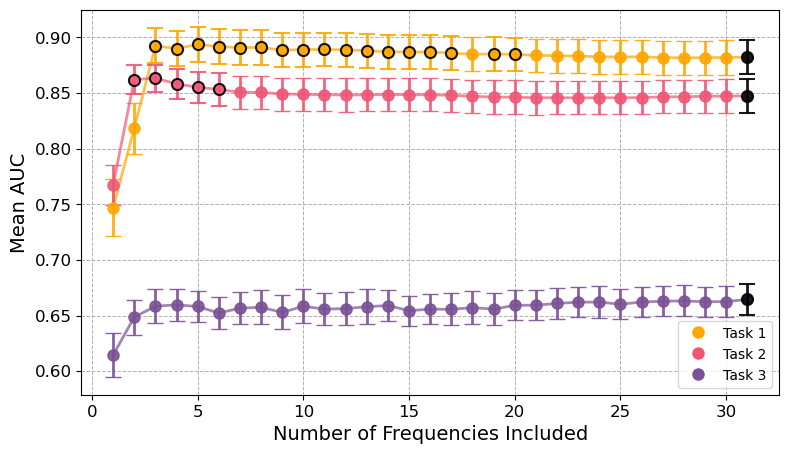

In [72]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import sem, t

custom_colors = ['#ffa600', '#ef5675', '#7a5195']

tasks = df_stats['Task'].unique()
# Sort so tasks are in numerical order
tasks_sorted = sorted(tasks, key=task_sort_key)

fsel_groups = sorted([f for f in df_stats['Fsel'].unique() if f != 'all'])

fig, ax = plt.subplots(figsize=(9, 5))

for i, task in enumerate(tasks_sorted):
    color = custom_colors[i % len(custom_colors)]  # cycle through colors
    
    means = []
    fsel_plot = []
    
    for fsel in fsel_groups:
        auc_data = df_stats[(df_stats['Task'] == task) & (df_stats['Fsel'] == fsel)]['auc'].values
        if len(auc_data) == 0:
            continue
        
        mean_auc = np.mean(auc_data)
        n = len(auc_data)
        std_err = sem(auc_data)
        h = std_err * t.ppf((1 + 0.95) / 2, n - 1) if n > 1 else 0
        
        res_row = df_results[(df_results['Task'] == task) & (df_results['Fsel'] == fsel)]
        if res_row.empty:
            h_val = 0
            t_stat = None
        else:
            h_val = int(res_row['h-val'].values[0])
            t_stat = res_row['T-stat'].values[0]
            
        # Determine color: use black if Fsel==31, else task color
        marker_color = 'black' if fsel == 31 else color

       # Edge color bold only if significant and not the black marker (keep black for significance on regular colors)
        if fsel == 31:
            edge_color = 'black'  # black marker gets black edge
            print(f"Mean auc for fsel 31: {mean_auc}")
        else:
            edge_color = 'black' if h_val == 1 and (t_stat is not None and t_stat > 0) else color
            
        ax.errorbar(fsel, mean_auc, yerr=h, fmt='o', color=marker_color, ecolor=marker_color,
                    elinewidth=2, capsize=6, capthick=2,
                    markersize=8,
                    markeredgecolor=edge_color, markeredgewidth=1.5 if edge_color == 'black' else 1,
                    alpha=0.9)

        means.append(mean_auc)
        fsel_plot.append(fsel)

    if len(fsel_plot) > 1:
        ax.plot(fsel_plot, means, color=color, linestyle='-', linewidth=2, alpha=0.7)

ax.set_xlabel('Number of Frequencies Included',fontsize=14)
ax.set_ylabel('Mean AUC',fontsize=14)
#ax.set_title('Mean AUC with 95% Confidence Interval by Task and Frequency inclusion')
ax.tick_params(axis='both', labelsize=12) 

from matplotlib.lines import Line2D
legend_handles = [Line2D([0], [0], marker='o', color='w', label=task,
                         markerfacecolor=custom_colors[i % len(custom_colors)], markersize=10) for i, task in enumerate(tasks_sorted)]
ax.legend(handles=legend_handles)

ax.grid(True, linestyle='--', linewidth=0.7)

# Save figure
plt.savefig("results/Freq_reduction_all_tasks_with_CI_markers.pdf", bbox_inches='tight')
plt.show()

# Get composite frequency rankings

In [73]:
from collections import defaultdict

# Composite frequency ranking calculation from df_overall
compiled_freq_results = []

for task in df_overall['Task'].unique():
    df_task = df_overall[df_overall['Task'] == task]
    
    total_rows = len(df_task)
    freq_points = defaultdict(float)
    
    for idx, row in df_task.iterrows():
        # Parse fold_top_freq_indices robustly
        freqs = parse_space_separated_array_str(row['fold_top_freq_indices'])
        
        for rank, freq in enumerate(freqs):
            freq_points[freq] += rank
    
    # Average points by total number of rows
    for freq in freq_points:
        freq_points[freq] /= total_rows
    
    # Sort ascending by average points (best first)
    freq_ranking_sorted = sorted(freq_points.items(), key=lambda x: x[1])
    sorted_freqs = [freq for freq, pts in freq_ranking_sorted]
    
    compiled_freq_results.append({
        'Task': task,
        'frequency_ranking': sorted_freqs
    })

df_freq_ranking = pd.DataFrame(compiled_freq_results)

# Get top 4 Fsel groups per Task from df_results
top_fsel_per_task = (
    df_results
    .sort_values(['Task', 'T-stat'], ascending=[True, False])
    .groupby('Task')
    .head(4)                        # top 4 rows per Task by T-stat
    .groupby('Task')['Fsel']        # group again to aggregate
    .apply(list)                    # collect Fsel into list
    .reset_index(name='best_fsel_groups')
)

# Merge top_fsel_groups into composite frequency ranking df by Task
df_final = pd.merge(df_freq_ranking, top_fsel_per_task, on='Task', how='left')
df_final.to_csv("results/task_freq_fsel_summary.csv", index=False)

print(df_final)

     Task                                  frequency_ranking  best_fsel_groups
0  Task 1  [30, 0, 12, 27, 29, 8, 13, 28, 16, 10, 26, 11,...      [5, 6, 8, 7]
1  Task 3  [30, 0, 12, 8, 7, 29, 13, 28, 11, 27, 16, 1, 2...  [23, 28, 24, 27]
2  Task 2  [30, 0, 12, 29, 8, 7, 13, 11, 16, 28, 27, 9, 1...      [3, 4, 2, 5]


Only non-signifcant results is from Top 12 frequencies in Task 2. So we can claim that tuning the included frequencies improves the AUCs

# IIVV pattern reduction

In [ ]:
# class_task = "healthy_vs_cancer"
# class_task = "cancer_vs_hbd"
# class_task = "MC"

In [ ]:
df_results = pd.read_csv(f"results/IIVV-analysis_{class_task}.csv")
df_params = pd.read_csv(f"results/IIVV-analysis_{class_task}_params.csv")

In [ ]:
# --- Heatmap figure ---
df_pivot = df_results.pivot(index="Mask", columns="Trial", values="avg. ROC AUC")
df_results_avg = df_pivot.mean(axis=1).reset_index()
df_results_avg.columns = ["Mask", "avg. ROC AUC"]

df_plot = pd.merge(df_params, df_results_avg, on="Mask")

mask_means = df_pivot.mean(axis=1)
# Sort descending by mean ROC AUC
order = mask_means.sort_values(ascending=False).index.tolist()
df_pivot = df_pivot.reindex(order)

fig1, ax0 = plt.subplots(figsize=(7, 5.5))
sns.heatmap(
    df_pivot,
    annot=True,
    cmap=cmap_gradient,
    cbar_kws={"label": "Mean AUC"},
    ax=ax0,
)
ax0.set_ylabel("Selected IIVV")
ax0.set_xlabel("Trial")
plt.tight_layout()
plt.savefig(f"results/IIVV_sel_heatmap_{class_task}.pdf", bbox_inches="tight")
plt.show()

In [ ]:
print("Ranked by best preformance")
print(mask_means[order])

In [ ]:
categories = df_plot["Mask"].unique()
base_palette = sns.color_palette(palette="hls", n_colors=len(categories) - 1)
palette = {}
i = 0
for cat in categories:
    if cat == "All":
        palette[cat] = "black"
    else:
        palette[cat] = base_palette[i]
        i += 1

fig2, ax1 = plt.subplots(figsize=(6, 3.8))
sns.scatterplot(
    data=df_plot,
    x="n_params",
    y="avg. ROC AUC",
    hue="Mask",
    palette=palette,
    s=50,
    ax=ax1,
)
ax1.set_xscale("log")
ax1.set_xlabel("Input data points $N_{input}$")
ax1.set_ylabel("Mean AUC")
ax1.grid(alpha=0.3)
ax1.legend(
    title="IIVV pattern", framealpha=0.4, bbox_to_anchor=(1, 1.02), loc="upper left"
)

plt.tight_layout()
plt.savefig(f"results/IIVV_sel_scatter_{class_task}.pdf", bbox_inches="tight")
plt.show()

## Statistical impact of IIVV maskimport numpy as np

In [6]:
from glob import glob

import matplotlib.pyplot as plt
import pandas as pd
import seaborn as sns
import numpy as np

files = glob("results/IIVV-analysis_*_statistics.csv")

dfs = []
df_stats = []

for file in files:
    df = pd.read_csv(file)
    dfs.append(df)

df_stats = pd.concat(dfs, ignore_index=True)

#df_stats = pd.read_csv(f"results/IIVV-analysis_full.csv")

mapping_t = {"healthy_vs_cancer": "Task 1", "cancer_vs_hbd": "Task 2", "MC": "Task 3"}
mapping_c = {
    "healthy_vs_cancer": "#58508D",
    "cancer_vs_hbd": "#FFA600",
    "MC": "#FF6361",
}
df_stats["Color"] = df_stats["Task"].map(mapping_c)
df_stats["Task"] = df_stats["Task"].map(mapping_t)

# Get rid of the exact threshold for each task
df_stats['IIVV'] = df_stats['IIVV'].str.replace(r'^z_threshold:.*', 'z_threshold', regex=True)

In [3]:
df_stats

,Task,IIVV,rs,auc,Fold,n_params,Color
0,Task 2,z_threshold,0,0.821549,NaN,NaN,#FFA600
1,Task 2,z_threshold,0,0.850926,NaN,NaN,#FFA600
2,Task 2,z_threshold,0,0.894231,NaN,NaN,#FFA600
3,Task 2,z_threshold,0,0.912500,NaN,NaN,#FFA600
4,Task 2,z_threshold,0,0.882576,NaN,NaN,#FFA600
...,...,...,...,...,...,...,...
2095,Task 3,z_threshold,9,0.795467,NaN,NaN,#FF6361
2096,Task 3,z_threshold,9,0.766156,NaN,NaN,#FF6361
2097,Task 3,z_threshold,9,0.620039,NaN,NaN,#FF6361
2098,Task 3,z_threshold,9,0.747658,NaN,NaN,#FF6361


T tests between different IIVV groups

In [8]:
# Frequency selections to compare 
iivv_comp = df_stats['IIVV'].unique()
#iivv_comp = [x for x in iivv_comp if x != 'All']    # exclude the "all" pattern
print(iivv_comp)

iivv_counts = {
    'Long a+': 16,
    'Long a+ ext.': 120,
    'Med. a+ ext.': 120,
    'Skip1 close' : 360,
    'Adj. close' :292,
    'Med. adj.' :387,
    'Adj. far' : 660,
    'Skip1 medium': 440, 
    'Skip1 far' : 224,
    'Opp. close': 264,
    'Opp. medium': 264,
    'Opp. far': 264,
    'All': 7728,
    'z_threshold': 2900,
}

['z_threshold' 'Long a+' 'Long a+ ext.' 'Med. a+ ext.' 'Skip1 close'
 'Adj. close' 'Med. adj.' 'Adj. far' 'Skip1 medium' 'Skip1 far'
 'Opp. close' 'Opp. medium' 'Opp. far' 'All']


In [9]:
from scipy.stats import ttest_rel, ttest_ind

# store stats results 
results = [] 

for task in df_stats['Task'].unique():
    df_task = df_stats[df_stats['Task'] == task]
    
    # get auc values from all IIVV patterns
    auc_all = df_task[df_task['IIVV'] == 'All']['auc'].values
    
    for iivv_set in iivv_comp:
        # get auc values for current iivv to test
        auc_iivv = df_task[df_task['IIVV'] == iivv_set]['auc'].values 
        
        # check that lengths match 
        if len(auc_all) == len(auc_iivv):
            # paired ttest 
            t_stat, p_val = ttest_rel(auc_iivv, auc_all)
        else: 
           # unpaired ttest 
            print(f"Unequal sample sizes for task {task}, IIVV set {iivv_set} --> unpaired ttest")
            t_stat, p_val = ttest_ind(auc_iivv, auc_all)
            
        h_val = 0 
        if p_val < 0.05: 
            h_val = 1
        results.append({'Task': task, 'IIVV': iivv_set, 'T-stat': t_stat, 'p-value': p_val, 'h-value': h_val, 'mean auc': np.mean(auc_iivv)}) 
    
    # Create a single DataFrame with all task results
    df_results = pd.DataFrame(results)

    # Create dataframe with task results and sort by descending T-stat
    df_task_results = pd.DataFrame(results)
    df_task_results = df_task_results[df_task_results['Task'] == task]
    df_task_results = df_task_results.sort_values(by='mean auc', ascending=False)
    
    print(f"Results for {task}:")
    print(df_task_results.to_string(index=False))
    print("\n" + "-"*50 + "\n")
                     

Results for Task 2:
  Task         IIVV    T-stat  p-value  h-value  mean auc
Task 2  z_threshold  2.659210 0.010552        1  0.857972
Task 2 Med. a+ ext.  2.678228 0.010045        1  0.855249
Task 2 Skip1 medium  2.143783 0.037039        1  0.854089
Task 2    Skip1 far  1.314484 0.194803        0  0.852889
Task 2     Adj. far  1.600586 0.115897        0  0.852548
Task 2   Adj. close  1.691425 0.097107        0  0.852499
Task 2  Opp. medium  0.537128 0.593610        0  0.849411
Task 2          All       NaN      NaN        0  0.847317
Task 2  Skip1 close -0.261189 0.795041        0  0.846826
Task 2   Opp. close -1.303123 0.198623        0  0.844733
Task 2    Med. adj. -2.268183 0.027761        1  0.843160
Task 2      Long a+ -1.832416 0.072970        0  0.842682
Task 2 Long a+ ext. -3.975874 0.000230        1  0.839457
Task 2     Opp. far -2.323028 0.024372        1  0.839210

--------------------------------------------------

Results for Task 1:
  Task         IIVV    T-stat      p-

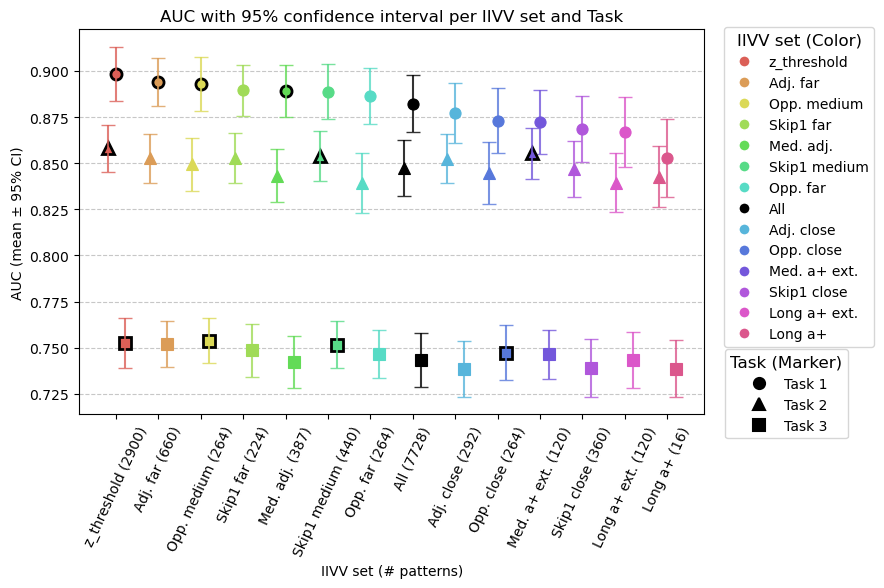

In [50]:
import matplotlib.pyplot as plt
import seaborn as sns
import numpy as np
import pandas as pd
from scipy.stats import sem, t
import re

# Helper: 95% CI calculation
def mean_ci(series, confidence=0.95):
    n = len(series)
    mean = np.mean(series)
    sem_val = sem(series)
    h = sem_val * t.ppf((1 + confidence) / 2., n-1) if n > 1 else 0
    return mean, mean - h, mean + h


def task_sort_key(task_label):
    match = re.search(r'\d+', task_label)
    return int(match.group()) if match else float('inf')

# Get unique Tasks and Masks
tasks = df_stats["Task"].unique()
masks = df_stats["IIVV"].unique()

# Sort so tasks are in numerical order
tasks_sorted = sorted(tasks, key=task_sort_key)

# Define marker styles per task
marker_styles = ['o', '^', 's']  # change or extend if needed
task_markers = {task: marker_styles[i] for i, task in enumerate(tasks_sorted)}

# Calculate mean aucs for each Mask (IIVV) for Task 1 only
mean_auc_task1 = df_stats[df_stats['Task'] == 'Task 1'].groupby('IIVV')['auc'].mean()

# Sort mask list by mean auc descending (or ascending)
masks_sorted = mean_auc_task1.sort_values(ascending=False).index.tolist()

# Use this sorted masks list for x-axis mapping
x_positions = np.arange(len(masks_sorted))
mask_to_x = {m: x for m, x in zip(masks_sorted, x_positions)}

# custom palette 
categories = masks_sorted
base_palette_seeds = sns.color_palette("hls", n_colors=len(categories) - 1)

palette = {}
i = 0
for cat in categories:
    if cat == "All":
        palette[cat] = (0, 0, 0)  # black as RGB tuple
    else:
        palette[cat] = base_palette_seeds[i]
        i += 1
        
fig, ax = plt.subplots(figsize=(10, 5))

# Prepare data for plotting
plot_data = []
for mask in masks:
    for task in tasks_sorted:
        subset = df_stats[(df_stats['IIVV'] == mask) & (df_stats['Task'] == task)]
        if len(subset) == 0:
            continue
        mean, ci_lower, ci_upper = mean_ci(subset['auc'])
        plot_data.append({
            'Mask': mask,
            'Task': task,
            'mean': mean,
            'ci_lower': ci_lower,
            'ci_upper': ci_upper
        })

plot_df = pd.DataFrame(plot_data)

# Merge h-value and T-stat into plot_df
plot_df = plot_df.merge(
    df_results[['IIVV', 'Task', 'h-value', 'T-stat']],
    left_on=['Mask', 'Task'],
    right_on=['IIVV', 'Task'],
    how='left'
)

# X-axis positions for each Mask - integer positions
x_positions = np.arange(len(masks_sorted))
mask_to_x = {m: x for m, x in zip(masks_sorted, x_positions)}

# Offset so markers for different tasks don’t exactly overlap
offset_map = {tasks[0]: -0.2, tasks[1]: 0, tasks[2]: 0.2}

for idx, row in plot_df.iterrows():
    base_color = palette.get(row['Mask'], (0.5, 0.5, 0.5))  # fallback grey if not found
    marker = task_markers.get(row['Task'], 'o')
    
    x = mask_to_x[row['Mask']] + offset_map[row['Task']]
    y = row['mean']
    
    # Condition for outlining:
    outline = (row['h-value'] == 1) and (row['T-stat'] > 0)

    edgecolor = 'black' if outline else base_color  # edge black if condition met, else same as facecolor
    edgewidth = 2 if outline else 0.8
    
    # Plot the mean as a marker, outline if statistically better than baseline
    ax.plot(x, y,
         marker=marker,
         color=base_color,
         markersize=8,
         linestyle='None',
         markeredgecolor=edgecolor,
         markeredgewidth=edgewidth)
    
    # Plot error bar
    ax.errorbar(
        x, y,
        yerr=[[y - row['ci_lower']], [row['ci_upper'] - y]],
        fmt='none',
        ecolor=base_color,
        capsize=5,
        alpha=0.8
    )

# Create new x tick labels with counts in parentheses
xtick_labels_with_counts = [f"{m} ({iivv_counts.get(m, 0)})" for m in masks_sorted]

plt.xticks(x_positions, xtick_labels_with_counts, rotation=65)

# Customize x-axis ticks and labels
#plt.xticks(x_positions, masks_sorted, rotation=65)
plt.xlabel("IIVV set (# patterns)")
plt.ylabel("AUC (mean ± 95% CI)")
plt.title("AUC with 95% confidence interval per IIVV set and Task")
plt.grid(axis='y', linestyle='--', alpha=0.7)

# Create legends

from matplotlib.lines import Line2D

# Legend for Masks (color)
mask_legend = [Line2D([0], [0], marker='o', color='w', label=mask,
                      markerfacecolor=palette[mask], markersize=8)
               for mask in categories]

# Legend for Tasks (marker styles, black color)
task_legend = [Line2D([0], [0], marker=task_markers[task], color='black', label=task,
                      markersize=8, linestyle='None', markeredgewidth=1.5)
               for task in tasks_sorted]

# Place legends outside plot area, stacked vertically
#leg1 = plt.legend(handles=mask_legend, title="IIVV set (Color)", ncols=1, bbox_to_anchor=(1.01, 1.02), loc='upper left')
#plt.gca().add_artist(leg1)

# Add Mask legend in upper right side of figure
fig.legend(handles=mask_legend,
           title="IIVV set (Color)",
           loc='upper right',
           bbox_to_anchor=(0.92, 0.884),
           borderaxespad=0.,
           fontsize='medium',
           title_fontsize='large')

# Add Task legend below Mask legend, aligned right
fig.legend(handles=task_legend,
           title="Task (Marker)",
           loc='upper right',
           bbox_to_anchor=(0.894, 0.24),
           borderaxespad=0.,
           fontsize='medium',
           title_fontsize='large')

#plt.legend(handles=task_legend, title="Task (Marker)", bbox_to_anchor=(1.01, -0.11), loc='lower left')

plt.subplots_adjust(right=0.75)  # Leave right 25% empty for legends

#plt.tight_layout(rect=[0,0,0.70,1])  # Make room on right for legends

# Save figure
plt.savefig("results/IIVV_analysis_all_tasks_with_CI_markers.pdf", bbox_inches='tight')
plt.show()

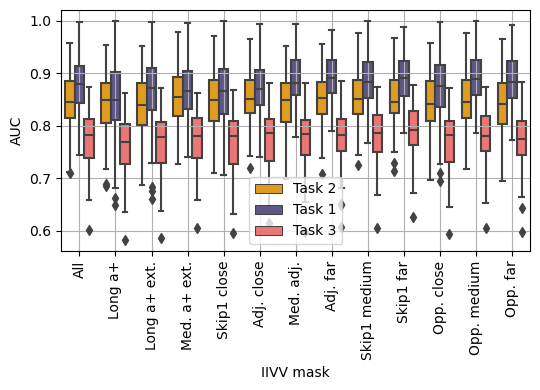

In [106]:
plt.figure(figsize=(5.5, 4))
sns.boxplot(
    data=df_stats,
    x="IIVV",
    y="auc",
    hue="Task",
    palette={
        task: color
        for task, color in zip(df_stats["Task"].unique(), df_stats["Color"].unique())
    },
    #gap=0.1,
)
plt.ylabel("AUC")
plt.grid()
plt.xlabel("IIVV mask")
plt.xticks(rotation=90)
plt.legend()
plt.tight_layout()
plt.savefig(f"results/IIVV-analysis_statistics.pdf", bbox_inches="tight")
plt.show()

___

# Model and parameter tuning results

- Tuning: 4 (best freq. sel) x 4 (best IIVV sel.) = 16 combinations
- Parameter tuning: SVM, RF, LR for baseline


In [1]:
import glob

import numpy as np
import pandas as pd
from toolbox.evaluation import load_top_Fsel_Msel

In [2]:
csv_files = glob.glob("results/LPOCV_*.csv")

if not csv_files:
    print("No matching file name found.")
else:
    for file in csv_files:
        try:
            df = pd.read_csv(file)
            print(f"{file}: {len(df)} Zeilen")
        except Exception as e:
            print(f"Error during loading {file}: {e}")

results\LPOCV_cancer_vs_hbd_All_All_model_HPT.csv: 23 Zeilen
results\LPOCV_healthy_vs_cancer_All_All_model_HPT.csv: 23 Zeilen
results\LPOCV_healthy_vs_cancer_Top 5_Med. a+ ext._model_HPT.csv: 230 Zeilen
results\LPOCV_MC_All_All_model_HPT.csv: 25 Zeilen
results\LPOCV_tuning_LR_cancer_vs_hbd.csv: 120 Zeilen
results\LPOCV_tuning_LR_healthy_vs_cancer.csv: 160 Zeilen
results\LPOCV_tuning_LR_MC.csv: 120 Zeilen
results\LPOCV_tuning_LR_z_thresh_cancer_vs_hbd.csv: 40 Zeilen
results\LPOCV_tuning_LR_z_thresh_healthy_vs_cancer.csv: 40 Zeilen
results\LPOCV_tuning_LR_z_thresh_MC.csv: 40 Zeilen
results\LPOCV_tuning_RF_cancer_vs_hbd.csv: 120 Zeilen
results\LPOCV_tuning_RF_healthy_vs_cancer.csv: 160 Zeilen
results\LPOCV_tuning_RF_MC.csv: 120 Zeilen
results\LPOCV_tuning_RF_z_thresh_cancer_vs_hbd.csv: 40 Zeilen
results\LPOCV_tuning_RF_z_thresh_healthy_vs_cancer.csv: 40 Zeilen
results\LPOCV_tuning_RF_z_thresh_MC.csv: 40 Zeilen
results\LPOCV_tuning_SVM_cancer_vs_hbd.csv: 120 Zeilen
results\LPOCV_tuning_SVM

In [3]:
tasks = ["healthy_vs_cancer", "cancer_vs_hbd", "MC"]
models = ["SVM", "RF", "LR"]

for class_task in tasks:
    # load frequency selection
    Freq_sel, Mask_sel = load_top_Fsel_Msel(class_task)

    for model in models:
        if model == models[0]:
            param_grid = {
                "kernel": ["linear", "poly", "rbf", "sigmoid"],
                "C": np.logspace(
                    -3, 3, 7, dtype=float
                ),  # [0.001, 0.01, 0.1, 1, 10, 100, 1000]
            }

        elif model == models[1]:
            param_grid = {
                "n_estimators": [100, 300, 500, 800],
                "max_depth": [510, 20, None],
                "max_features": ["sqrt", "log2"],
                "min_samples_split": [2, 5, 10],
                "min_samples_leaf": [1, 2, 4],
            }
        elif model == models[2]:
            param_grid = {
                "C": [0.01, 0.1, 1, 10, 100],
                "max_iter": [100, 1000, 10_000],
            }
        keys = list(param_grid.keys())

        print("\n%----------------------------%")
        print(f"\t{class_task}")
        print(f"\t{model}")

        #df = pd.read_csv(f"results/LPOCV_tuning_{model}_{class_task}.csv")
        pattern = f"results/LPOCV_tuning_{model}*_{class_task}.csv"
        matching_files = glob.glob(pattern)
        
        dfs = []
        for file in matching_files:
            try:
                df_temp = pd.read_csv(file)
                dfs.append(df_temp)
            except Exception as e:
                print(f"Error during loading {file}: {e}")
       
        df = pd.concat(dfs, ignore_index=True)
    
        print("Top Frequencies")
        for Fsel, val in Freq_sel.items():
            print("\t", Fsel, ":", val)
        print("Top IIVVs")
        for Msel in Mask_sel.keys():
            print("\t", Msel)
        print("\n")
        df["hpt_combinations"] = df.apply(
            lambda row: "_".join([str(row[k]) for k in keys]), axis=1
        )

        df["Fsel_Msel"] = df.apply(
            lambda row: "_".join([str(row[k]) for k in ["Fsel", "Msel"]]), axis=1
        )

        result = df.groupby("hpt_combinations")["val AUC"].mean().reset_index()
        print(result)

        for col in ["hpt_combinations"]:
            print(f"\nColumn: {col}")
            print(df[col].value_counts())

        # get most important tuning comb
        top_hpt = df["hpt_combinations"].value_counts().idxmax()
        print(f"\nMost counted hpt_combinations: {top_hpt}")

        fsel_msel_counts = (
            df.loc[df["hpt_combinations"] == top_hpt, "Fsel_Msel"]
            .value_counts()
            .reset_index()
            .rename(columns={"index": "Fsel_Msel", "Fsel_Msel": "count"})
        )

        print(f"\nRelated Fsel_Msel etries for {top_hpt}")
        print(fsel_msel_counts)

        print("%----------------------------%")


%----------------------------%
	healthy_vs_cancer
	SVM
Top Frequencies
	 Top 1 : [30]
	 Top 2 : [30, 0]
	 Top 3 : [30, 0, 27]
	 Top 4 : [30, 0, 27, 12]
	 Top 5 : [30, 0, 27, 12, 29]
	 Top 6 : [30, 0, 27, 12, 29, 8]
	 Top 7 : [30, 0, 27, 12, 29, 8, 28]
	 Top 8 : [30, 0, 27, 12, 29, 8, 28, 13]
	 Top 9 : [30, 0, 27, 12, 29, 8, 28, 13, 16]
	 Top 10 : [30, 0, 27, 12, 29, 8, 28, 13, 16, 26]
	 Top 11 : [30, 0, 27, 12, 29, 8, 28, 13, 16, 26, 10]
	 Top 12 : [30, 0, 27, 12, 29, 8, 28, 13, 16, 26, 10, 11]
	 Top 13 : [30, 0, 27, 12, 29, 8, 28, 13, 16, 26, 10, 11, 25]
	 Top 14 : [30, 0, 27, 12, 29, 8, 28, 13, 16, 26, 10, 11, 25, 17]
	 Top 15 : [30, 0, 27, 12, 29, 8, 28, 13, 16, 26, 10, 11, 25, 17, 1]
	 Top 16 : [30, 0, 27, 12, 29, 8, 28, 13, 16, 26, 10, 11, 25, 17, 1, 24]
	 Top 17 : [30, 0, 27, 12, 29, 8, 28, 13, 16, 26, 10, 11, 25, 17, 1, 24, 20]
	 Top 18 : [30, 0, 27, 12, 29, 8, 28, 13, 16, 26, 10, 11, 25, 17, 1, 24, 20, 15]
	 Top 19 : [30, 0, 27, 12, 29, 8, 28, 13, 16, 26, 10, 11, 25, 17, 1, 24

Top Frequencies
	 Top 1 : [30]
	 Top 2 : [30, 0]
	 Top 3 : [30, 0, 7]
	 Top 4 : [30, 0, 7, 12]
	 Top 5 : [30, 0, 7, 12, 29]
	 Top 6 : [30, 0, 7, 12, 29, 8]
	 Top 7 : [30, 0, 7, 12, 29, 8, 13]
	 Top 8 : [30, 0, 7, 12, 29, 8, 13, 16]
	 Top 9 : [30, 0, 7, 12, 29, 8, 13, 16, 27]
	 Top 10 : [30, 0, 7, 12, 29, 8, 13, 16, 27, 28]
	 Top 11 : [30, 0, 7, 12, 29, 8, 13, 16, 27, 28, 11]
	 Top 12 : [30, 0, 7, 12, 29, 8, 13, 16, 27, 28, 11, 15]
	 Top 13 : [30, 0, 7, 12, 29, 8, 13, 16, 27, 28, 11, 15, 26]
	 Top 14 : [30, 0, 7, 12, 29, 8, 13, 16, 27, 28, 11, 15, 26, 10]
	 Top 15 : [30, 0, 7, 12, 29, 8, 13, 16, 27, 28, 11, 15, 26, 10, 9]
	 Top 16 : [30, 0, 7, 12, 29, 8, 13, 16, 27, 28, 11, 15, 26, 10, 9, 23]
	 Top 17 : [30, 0, 7, 12, 29, 8, 13, 16, 27, 28, 11, 15, 26, 10, 9, 23, 20]
	 Top 18 : [30, 0, 7, 12, 29, 8, 13, 16, 27, 28, 11, 15, 26, 10, 9, 23, 20, 1]
	 Top 19 : [30, 0, 7, 12, 29, 8, 13, 16, 27, 28, 11, 15, 26, 10, 9, 23, 20, 1, 24]
	 Top 20 : [30, 0, 7, 12, 29, 8, 13, 16, 27, 28, 11, 15, 26, 

## Pattern and Parameters

In [ ]:
from toolbox.evaluation import load_top_Fsel_Msel

In [ ]:
class_tasks = ["healthy_vs_cancer", "cancer_vs_hbd", "MC"]

for class_task in class_tasks:
    print(class_task, "\n")
    Freq_sel, _ = load_top_Fsel_Msel(class_task)
    print(Freq_sel["Top 12"] + 1)

## ROC plots

In [34]:
glob("results/ROC*.npz")

['results\\ROC_default_cancer_vs_hbd_LR.npz',
 'results\\ROC_default_cancer_vs_hbd_LR_baseline.npz',
 'results\\ROC_default_cancer_vs_hbd_RF.npz',
 'results\\ROC_default_cancer_vs_hbd_RF_baseline.npz',
 'results\\ROC_default_cancer_vs_hbd_SVM.npz',
 'results\\ROC_default_cancer_vs_hbd_SVM_baseline.npz',
 'results\\ROC_default_healthy_vs_cancer_LR.npz',
 'results\\ROC_default_healthy_vs_cancer_LR_baseline.npz',
 'results\\ROC_default_healthy_vs_cancer_RF.npz',
 'results\\ROC_default_healthy_vs_cancer_RF_baseline.npz',
 'results\\ROC_default_healthy_vs_cancer_SVM.npz',
 'results\\ROC_default_healthy_vs_cancer_SVM_baseline.npz',
 'results\\ROC_default_MC_LR.npz',
 'results\\ROC_default_MC_LR_baseline.npz',
 'results\\ROC_default_MC_RF.npz',
 'results\\ROC_default_MC_RF_baseline.npz',
 'results\\ROC_default_MC_SVM.npz',
 'results\\ROC_default_MC_SVM_baseline.npz',
 'results\\ROC_tuned_cancer_vs_hbd_LR.npz',
 'results\\ROC_tuned_cancer_vs_hbd_LR_baseline.npz',
 'results\\ROC_tuned_cancer_vs

In [35]:
np.load(f"results/ROC_tuned_MC_SVM.npz", allow_pickle=True)

NpzFile 'results/ROC_tuned_MC_SVM.npz' with keys: info, MC_save_npz, class_task

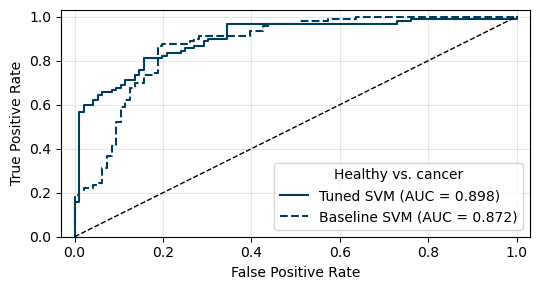

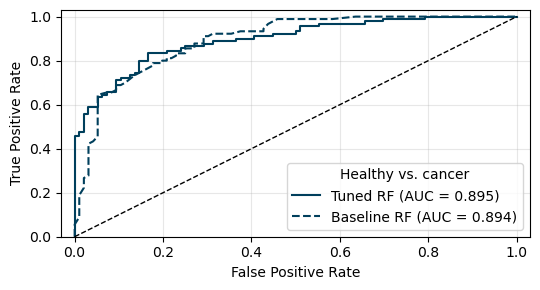

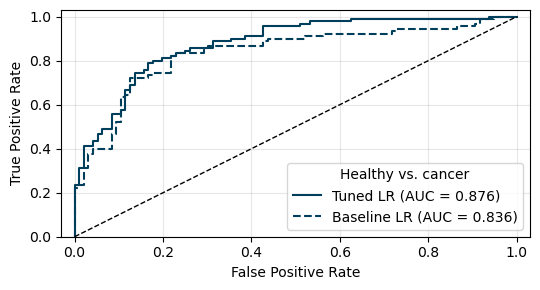

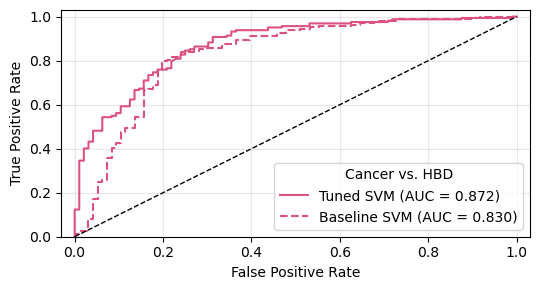

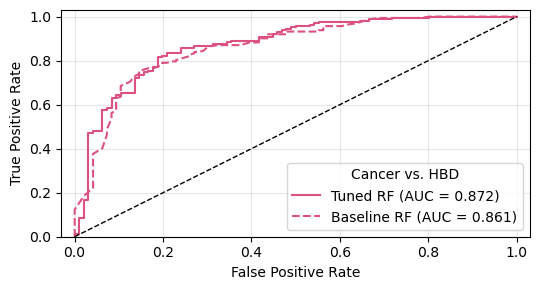

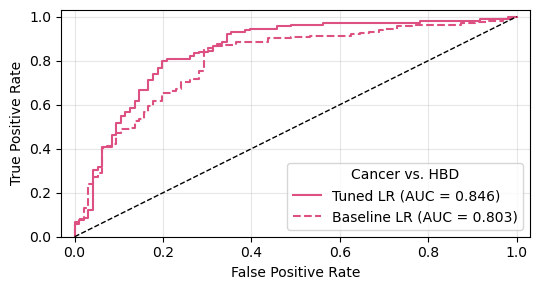

In [41]:
models = ["SVM", "RF", "LR"]
class_tasks = ["healthy_vs_cancer", "cancer_vs_hbd"]

label_roc_plot = {
    "healthy_vs_cancer": "Healthy vs. cancer",
   "cancer_vs_hbd": "Cancer vs. HBD",
    "MC": 'Multiclass'
}


for class_task in class_tasks:
    for model in models:
        tuned = np.load(
            f"results/ROC_tuned_{class_task}_{model}.npz", allow_pickle=True
        )
        baseline = np.load(
            f"results/ROC_default_{class_task}_{model}_baseline.npz", allow_pickle=True
        )

        s_name = f"results/ROC_baseline_tuned_{class_task}_{model}_combined.pdf"

        plt.figure(figsize=(5.5, 3))
        plt.plot(
            tuned["fpr"],
            tuned["tpr"],
            color=tuned["color"].tolist(),
            label= f"Tuned {model} (AUC = {tuned['roc_auc']:.3f})",
        )
        plt.plot(
            baseline["fpr"],
            baseline["tpr"],
            "--",
            color=baseline["color"].tolist(),
            label=f"Baseline {model} (AUC = {baseline['roc_auc']:.3f})",
        )
        plt.plot([0, 1], [0, 1], "k--", linewidth=1)
        plt.xlim([-0.03, 1.03])
        plt.ylim([0.0, 1.03])
        plt.grid()
        plt.xlabel("False Positive Rate")
        plt.ylabel("True Positive Rate")
        plt.legend(loc="lower right", title=label_roc_plot[class_task])
        plt.grid(alpha=0.3)
        plt.tight_layout()
        if s_name != None:
            plt.savefig(s_name, bbox_inches="tight")

## Timings

In [ ]:
cp = {
    "Baseline": "#FF6361",
    "Tuned": "#A1D99B",
}

In [ ]:
import glob

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns

label_roc_plot = {
    "healthy_vs_cancer": "Task 1",
    "cancer_vs_hbd": "Task 2",
    "MC": "Task 3",
}

files = glob.glob("results/timings_default*.npz")

records = []
for f in files:
    data = np.load(f, allow_pickle=True)
    model_type = str(data["model_type"])
    model = str(data["model"])
    class_task = str(data["class_task"])
    timings = data["timings_CV_iter"]

    for t in timings:
        records.append(
            {
                "model_type": model_type,
                "model": model,
                "class_task": label_roc_plot[class_task],
                "timing": t,
            }
        )

df = pd.DataFrame(records)
print(df.head())

df["group"] = df["class_task"] + "\n" + df["model"]
plt.figure(figsize=(5.5, 3))
sns.barplot(data=df, x="group", y="timing", hue="model_type", palette=cp)
plt.xticks(rotation=0)
plt.ylabel("Time per fold in s")
plt.xlabel("")
plt.yscale("log")
plt.legend(title="Model parameter")
plt.grid()
plt.tight_layout()
plt.savefig("results/timings_for_default_param_models.pdf", bbox_inches="tight")

In [ ]:
files = glob.glob("results/timings_tuned*.npz")

records = []
for f in files:
    data = np.load(f, allow_pickle=True)
    model_type = str(data["model_type"])
    model = str(data["model"])
    class_task = str(data["class_task"])
    timings = data["timings_CV_iter"]

    for t in timings:
        records.append(
            {
                "model_type": model_type,
                "model": model,
                "class_task": label_roc_plot[class_task],
                "timing": t,
            }
        )

df = pd.DataFrame(records)
print(df.head())

df["group"] = df["class_task"] + "\n" + df["model"]
plt.figure(figsize=(5.5, 3))
sns.barplot(data=df, x="group", y="timing", hue="model_type", palette=cp)
plt.xticks(rotation=0)
plt.ylabel("Time per fold in s")
plt.xlabel("")
plt.yscale("log")
plt.legend(title="Model parameter")
plt.grid()
plt.tight_layout()
plt.savefig("results/timings_for_tuned_param_models.pdf", bbox_inches="tight")

In [ ]:
files_1 = glob.glob("results/timings_tuned*_SVM.npz")
files_3 = glob.glob("results/timings_tuned*_RF.npz")
files_2 = glob.glob("results/timings_tuned*_LR.npz")
files_4 = glob.glob("results/timings_default*baseline.npz")
files = files_1 + files_2 + files_3 + files_4

records = []
for f in files:
    data = np.load(f, allow_pickle=True)
    model_type = str(data["model_type"])
    model = str(data["model"])
    class_task = str(data["class_task"])
    timings = data["timings_CV_iter"]

    for t in timings:
        records.append(
            {
                "model_type": model_type,
                "model": model,
                "class_task": label_roc_plot[class_task],
                "timing": t,
            }
        )

df = pd.DataFrame(records)
print(df.head())

df["group"] = df["class_task"] + "\n" + df["model"]
plt.figure(figsize=(5.5, 3))
sns.barplot(data=df, x="group", y="timing", hue="model_type", palette=cp)
plt.xticks(rotation=0)
plt.ylabel("Time per fold in s")
plt.xlabel("")
plt.yscale("log")
plt.legend(title="Model parameter")
plt.grid()
plt.tight_layout()
plt.savefig(
    "results/timings_for_tuned_vs_default_param_models.pdf", bbox_inches="tight"
)

## Visualize IIVV mask

In [ ]:
import matplotlib.pyplot as plt
import numpy as np
from toolbox import Masking

In [ ]:
IIVV = np.loadtxt("source/IIVV_patterns.txt", dtype=int)
mask = Masking(IIVV)

In [ ]:
# load masking selection
Mask_sel = {
    "All": "all",
    "Long a+": "vv_long_across",
    "Long a+ ext.": "vv_long_across_extended",
    "Med. a+ ext.": "vv_medium_across_extended",
    "Skip1 close": "vv_distance_close_skip_1",
    "Adj. close": "adjacent_close",
    "Med. adj.": "vv_distance_medium_adj",
    "Adj. far": "adjacent_far",
    "Skip1 medium": "skip1_medium",
    "Skip1 far": "skip1_far",
    "Opp. close": "opposite_close",
    "Opp. medium": "opposite_medium",
    "Opp. far": "opposite_far",
}

In [ ]:
mask.prints = False


def plot_Mask(mask, mode="horizontal", title=None, s_name=None):

    if mode == "horizontal":
        plt.figure(figsize=(6, 2.2))
        plt.plot(
            np.where(mask.mask)[0],
            mask.IIVV[mask.mask][:, 0],
            ".",
            markersize=1,
            label="$I_0$",
        )
        plt.plot(
            np.where(mask.mask)[0],
            mask.IIVV[mask.mask][:, 1],
            ".",
            markersize=1,
            label="$I_1$",
        )
        plt.plot(
            np.where(mask.mask)[0],
            mask.IIVV[mask.mask][:, 2],
            ".",
            markersize=1,
            label="$V_0$",
        )
        plt.plot(
            np.where(mask.mask)[0],
            mask.IIVV[mask.mask][:, 3],
            ".",
            markersize=1,
            label="$V_1$",
        )
        plt.xlabel("IIVV index")
        plt.ylabel("Electrode no.")
        plt.grid()
        plt.legend()
        plt.tight_layout()
        if title:
            plt.title(title)
        if s_name != None:
            plt.savefig(s_name, bbox_inches="tight")
        plt.show()
    if mode == "vertical":
        plt.figure(figsize=(2, 6))
        plt.plot(
            mask.IIVV[mask.mask][:, 0],
            np.where(mask.mask)[0],
            ".",
            markersize=1,
            label="$I_0$",
        )
        plt.plot(
            mask.IIVV[mask.mask][:, 1],
            np.where(mask.mask)[0],
            ".",
            markersize=1,
            label="$I_1$",
        )
        plt.plot(
            mask.IIVV[mask.mask][:, 2],
            np.where(mask.mask)[0],
            ".",
            markersize=1,
            label="$V_0$",
        )
        plt.plot(
            mask.IIVV[mask.mask][:, 3],
            np.where(mask.mask)[0],
            ".",
            markersize=1,
            label="$V_1$",
        )
        plt.ylabel("IIVV index")
        plt.xlabel("Electrode no.")
        # plt.yticks(ticks=np.arange(len(mask.mask)),labels=np.arange(len(mask.mask)))
        plt.grid()
        plt.legend()
        plt.tight_layout()
        if title:
            plt.title(title)
        if s_name != None:
            plt.savefig(s_name, bbox_inches="tight")
        plt.show()

In [ ]:
for Msel in Mask_sel:
    mask.IIVV_mask(Mask_sel[Msel], plot=False)
    plot_Mask(
        mask,
        mode="horizontal",
        title=None,
        s_name=f"results/IIVV_pattern_{Mask_sel[Msel]}.pdf",
    )

In [ ]:
caption_names = {
    "all": r"\textit{All}",
    "vv_long_across": r"\textit{Long a+}",
    "vv_long_across_extended": r"\textit{Long a+ ext.}",
    "vv_medium_across_extended": r"\textit{Med. a+ ext.}",
    "vv_distance_close_skip_1": r"\textit{Skip1 far}",
    "adjacent_close": r"\textit{Opp. close}",
    "vv_distance_medium_adj": r"\textit{Opp. medium}",
    "adjacent_far": r"\textit{Opp. far}",
    "skip1_medium": r"\textit{Adj. close}",
    "skip1_far": r"\textit{Skip1 close}",
    "opposite_close": r"\textit{Med. adj.}",
    "opposite_medium": r"\textit{Skip1 medium} ",
    "opposite_far": r"\textit{Adj. far}",
}

with open("results/IIVVlatex.txt", "w", encoding="utf-8") as f:
    for values in Mask_sel.values():
        f.write(r"\begin{figure}[H]" + "\n")
        f.write(r"    \centering" + "\n")
        f.write(
            r"    \includegraphics[width=0.8\columnwidth]{figures/IIVVmasks/IIVV_pattern_"
            + f"{values}"
            + r".pdf}"
            + "\n"
        )
        f.write(r"    \caption{IIVV mask " + f"{caption_names[values]}" + r"}" + "\n")
        f.write(r"    \label{appendix:fig:IIVV:" + f"{values}" + r"}" + "\n")
        f.write(r"\end{figure}" + "\n\n")

___